# Remake -- training data preparation

Input: `cache/remake_dataset.parquet`, built by `remake_dataset.ipynb`.

Processing follows `final.ipynb` section 14. Steps that were already done
when the dataset was built are **not** repeated:

- Row filters (zoning, units of use, freehold, single-property, arm's-length,
  LINZ-matched) and removal of exact duplicate sales.
- Leakage columns removed (`capital_value`, `land_value`, net/chattels/other price).
- Categorical columns cast to string, missing filled with `"Unknown"`.
- `log1p` already applied to `land_area`, `building_total_floor_area`,
  `mass_total_floor_area`, `walk_supermarket_network_m`, `walk_bus_stop_network_m`
  -- applying it again here would double-log them.

What remains is done **inside each time-based fold, fitted on the training
rows only**, exactly as in `final.ipynb`: category encoding, bool to int,
median fill for missing numbers, and the 1st/99th-percentile price trim.

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import OrdinalEncoder

pd.set_option("display.max_columns", 70)

df = pd.read_parquet("./cache/remake_dataset.parquet")

# TimeSeriesSplit assumes row order IS time order -- sort explicitly rather
# than relying on the order the parquet was written in.
df = df.sort_values("sale_date_parsed").reset_index(drop=True)
print(f"Loaded {df.shape[0]:,} rows, {df.shape[1]} columns")
print(f"Date range: {df['sale_date_parsed'].min().date()} to {df['sale_date_parsed'].max().date()}")

Loaded 59,708 rows, 33 columns
Date range: 2024-01-01 to 2026-08-18


## 1. Feature groups

In [2]:
ID_COLS = ["valuation_id_concat", "sale_id", "sale_date_parsed"]
TARGET = "sale_price_gross"

CAT_COLS = [
    "property_type", "building_age_indicator", "building_condition_indicator",
    "building_construction_indicator", "noise_category_combination",
]
BOOL_COLS = ["in_flood_plain"]
NUM_COLS = [
    # property
    "land_area", "building_total_floor_area", "mass_total_floor_area",
    "off_street_parking", "mass_garage_under_main_roof", "mass_garage_freestanding",
    # location / spatial
    "latitude", "longitude", "distance_to_cbd", "walk_supermarket_network_m",
    "walk_bus_stop_network_m", "distance_to_school", "area_level_deprivation_index",
    # socioeconomic
    "median_personal_income_by_sa", "employment_rate_by_sa", "unemployment_rate_by_sa",
    "population_counts_by_sa", "population_density",
    # environment
    "distance_to_coastline",
    # market / time
    "building_consents", "sale_year", "sale_month", "sale_quarter",
]
FEATURE_COLS = CAT_COLS + BOOL_COLS + NUM_COLS

unassigned = set(df.columns) - set(FEATURE_COLS) - set(ID_COLS) - {TARGET}
missing = set(FEATURE_COLS) - set(df.columns)
assert not unassigned, f"Columns not assigned to any group: {unassigned}"
assert not missing, f"Feature columns not in dataset: {missing}"

print(f"{len(FEATURE_COLS)} features: {len(CAT_COLS)} categorical, {len(BOOL_COLS)} boolean, {len(NUM_COLS)} numeric")

29 features: 5 categorical, 1 boolean, 23 numeric


# 1.1 Correlation Heatmap


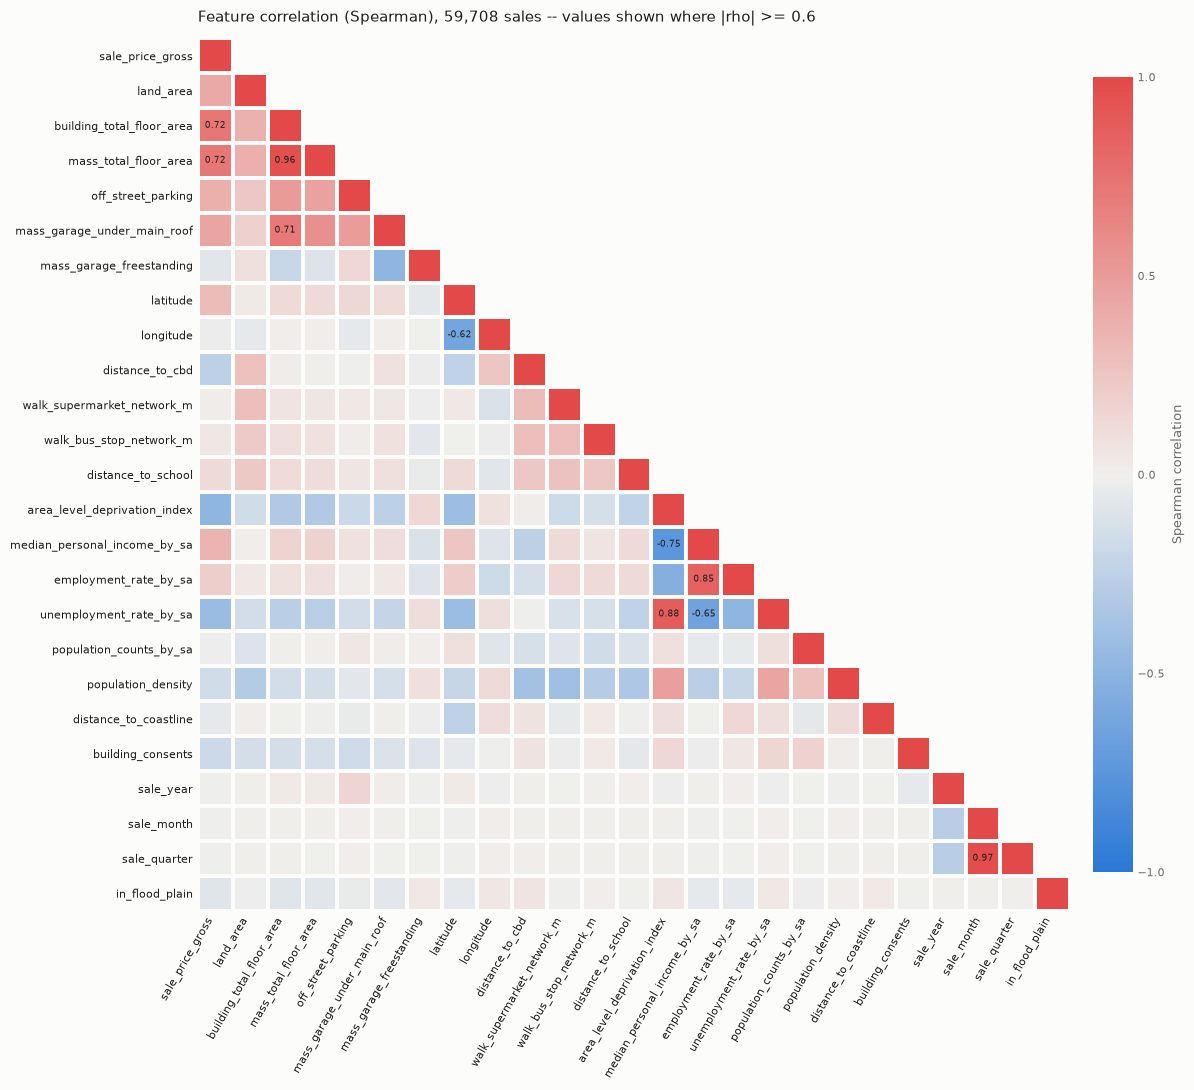

In [3]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Categorical columns are integer codes after encoding -- their correlations
# are meaningless, so only numeric + boolean features and the target go in.
CORR_COLS = [TARGET] + NUM_COLS + BOOL_COLS

# Spearman (rank) correlation: robust to the skewed distance/price columns.
corr = df[CORR_COLS].astype(float).corr(method="spearman")

SURFACE = "#fcfcfb"
INK = "#1f1f1e"
INK_MUTED = "#6b6b68"
diverging = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])

mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
shown = corr.mask(mask)
n = len(CORR_COLS)

fig, ax = plt.subplots(figsize=(13, 11), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
mesh = ax.pcolormesh(
    np.arange(n + 1), np.arange(n + 1), shown.values,
    cmap=diverging, vmin=-1, vmax=1, edgecolors=SURFACE, linewidth=1.5,
)
ax.invert_yaxis()
ax.set_aspect("equal")
ax.set_xticks(np.arange(n) + 0.5)
ax.set_yticks(np.arange(n) + 0.5)
ax.set_xticklabels(CORR_COLS, rotation=60, ha="right", fontsize=8, color=INK)
ax.set_yticklabels(CORR_COLS, fontsize=8, color=INK)
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)

# Label only strong pairs (|rho| >= 0.6) so the grid stays readable;
# every pair above that threshold is listed in the table below.
for i in range(n):
    for j in range(i):
        v = corr.iat[i, j]
        if abs(v) >= 0.6:
            ax.text(j + 0.5, i + 0.5, f"{v:.2f}", ha="center", va="center", fontsize=6.5, color=INK)

cbar = fig.colorbar(mesh, ax=ax, fraction=0.035, pad=0.02, ticks=[-1, -0.5, 0, 0.5, 1])
cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=8, colors=INK_MUTED, length=0)
cbar.set_label("Spearman correlation", fontsize=9, color=INK_MUTED)

ax.set_title(
    f"Feature correlation (Spearman), {len(df):,} sales -- values shown where |rho| >= 0.6",
    fontsize=11, color=INK, loc="left", pad=12,
)
plt.tight_layout()
plt.savefig("figures/correlation_heatmap.png", dpi=200, bbox_inches="tight", facecolor=SURFACE)
plt.show()

In [4]:
pairs = corr.where(np.tril(np.ones_like(corr, dtype=bool), k=-1)).stack().rename("spearman")
strong = pairs[pairs.abs() >= 0.6].sort_values(key=abs, ascending=False)
print(f"Pairs with |rho| >= 0.6: {len(strong)}")
display(strong.round(2).to_frame())

print("\nCorrelation with sale price (strongest first):")
corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(2).to_frame("spearman_vs_price")

Pairs with |rho| >= 0.6: 10


,,spearman
sale_quarter,sale_month,0.97
mass_total_floor_area,building_total_floor_area,0.96
unemployment_rate_by_sa,area_level_deprivation_index,0.88
employment_rate_by_sa,median_personal_income_by_sa,0.85
median_personal_income_by_sa,area_level_deprivation_index,-0.75
mass_total_floor_area,sale_price_gross,0.72
building_total_floor_area,sale_price_gross,0.72
mass_garage_under_main_roof,building_total_floor_area,0.71
unemployment_rate_by_sa,median_personal_income_by_sa,-0.65
longitude,latitude,-0.62



Correlation with sale price (strongest first):


,spearman_vs_price
mass_total_floor_area,0.72
building_total_floor_area,0.72
area_level_deprivation_index,-0.49
mass_garage_under_main_roof,0.45
unemployment_rate_by_sa,-0.43
land_area,0.42
off_street_parking,0.39
median_personal_income_by_sa,0.36
latitude,0.31
distance_to_cbd,-0.26


## 2. Missing values before processing

In [5]:
na = df[FEATURE_COLS + [TARGET]].isna().sum()
na[na > 0].to_frame("missing rows")

,missing rows
walk_supermarket_network_m,1596
walk_bus_stop_network_m,852


## 3. Per-fold processing (same steps as `final.ipynb` section 14.3)

Everything is learned from the training rows of a fold and then applied to
that fold's test rows, so no information from the test period leaks in.

In [6]:
def prepare_fold(train_df, test_df):
    """Encode, impute and price-trim one fold. Returns X/y for train and test."""
    encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    encoder.fit(train_df[CAT_COLS])

    X_train = train_df[FEATURE_COLS].copy()
    X_test = test_df[FEATURE_COLS].copy()
    X_train[CAT_COLS] = encoder.transform(train_df[CAT_COLS])
    X_test[CAT_COLS] = encoder.transform(test_df[CAT_COLS])
    for col in BOOL_COLS:
        X_train[col] = X_train[col].astype(int)
        X_test[col] = X_test[col].astype(int)
    X_train = X_train.astype(float)
    X_test = X_test.astype(float)

    nan_cols = [c for c in NUM_COLS if X_train[c].isna().any() or X_test[c].isna().any()]
    train_medians = X_train[nan_cols].median()
    X_train[nan_cols] = X_train[nan_cols].fillna(train_medians)
    X_test[nan_cols] = X_test[nan_cols].fillna(train_medians)

    y_train = train_df[TARGET].values
    y_test = test_df[TARGET].values
    p1, p99 = np.quantile(y_train, [0.01, 0.99])
    train_keep = (y_train >= p1) & (y_train <= p99)
    test_keep = (y_test >= p1) & (y_test <= p99)

    return {
        "X_train": X_train[train_keep], "y_train": y_train[train_keep],
        "X_test": X_test[test_keep], "y_test": y_test[test_keep],
        "test_idx": test_df.index[test_keep], "price_limits": (p1, p99),
    }

## 4. Build the 5 folds and check them

In [7]:
kf = TimeSeriesSplit(n_splits=5)
folds = []
rows = []
for fold_i, (train_idx, test_idx) in enumerate(kf.split(df), start=1):
    f = prepare_fold(df.iloc[train_idx], df.iloc[test_idx])
    assert not f["X_train"].isna().any().any() and not f["X_test"].isna().any().any()
    folds.append(f)
    rows.append({
        "fold": fold_i,
        "train_period_end": df.iloc[train_idx]["sale_date_parsed"].max().date(),
        "test_period": f"{df.iloc[test_idx]['sale_date_parsed'].min().date()} to {df.iloc[test_idx]['sale_date_parsed'].max().date()}",
        "n_train": len(f["y_train"]), "n_test": len(f["y_test"]),
        "price_p1": f["price_limits"][0], "price_p99": f["price_limits"][1],
    })

fold_summary = pd.DataFrame(rows).set_index("fold")
print(f"Total test rows across folds: {fold_summary['n_test'].sum():,}")
fold_summary

Total test rows across folds: 48,777


,train_period_end,test_period,n_train,n_test,price_p1,price_p99
fold,,,,,,
1,2024-06-19,2024-06-19 to 2024-11-07,9760,9779,450000.0,4512000.0
2,2024-11-07,2024-11-07 to 2025-04-01,19505,9685,450000.0,4229700.0
3,2025-04-01,2025-04-01 to 2025-08-22,29263,9783,430000.0,4261500.0
4,2025-08-22,2025-08-22 to 2026-01-24,39008,9761,433089.1,4219250.0
5,2026-01-24,2026-01-24 to 2026-08-18,48774,9769,430243.6,4200000.0


## 5. Train Random Forest, XGBoost and CatBoost

All three are trained on the same 5 folds and the same processed inputs, so
differences come from the model, not the data. Settings are fixed (not
tuned per model): Random Forest and XGBoost use the same settings as the
rest of this project (`loc_exp.ipynb`, `final.ipynb`); CatBoost is set to
match XGBoost (500 trees, depth 6, learning rate 0.05).

CatBoost could encode categories itself, but here it gets the same
integer-coded inputs as the other two to keep the comparison fair.

In [8]:
import time
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor


def rmse(y, yhat):
    return np.sqrt(np.mean((y - yhat) ** 2))


def mae(y, yhat):
    return np.mean(np.abs(y - yhat))


def mape(y, yhat):
    return np.mean(np.abs((y - yhat) / y)) * 100


MODELS = {
    "RandomForest": lambda: RandomForestRegressor(
        n_estimators=150, max_depth=18, min_samples_leaf=2, n_jobs=-1, random_state=42,
    ),
    "XGBoost": lambda: XGBRegressor(
        n_estimators=500, max_depth=6, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1,
    ),
    "CatBoost": lambda: CatBoostRegressor(
        iterations=500, depth=6, learning_rate=0.05, random_seed=42, thread_count=-1, verbose=0,
    ),
}

oof = pd.DataFrame(
    {
        "actual": np.concatenate([f["y_test"] for f in folds]),
        "fold": np.concatenate([np.full(len(f["y_test"]), i) for i, f in enumerate(folds, start=1)]),
    },
    index=np.concatenate([f["test_idx"] for f in folds]),
)
fold_rows = []
train_seconds = {}

for name, make_model in MODELS.items():
    start = time.time()
    preds = []
    for fold_i, f in enumerate(folds, start=1):
        model = make_model()
        model.fit(f["X_train"], f["y_train"])
        pred = model.predict(f["X_test"])
        preds.append(pred)
        fold_rows.append({
            "model": name, "fold": fold_i,
            "RMSE": rmse(f["y_test"], pred), "MAE": mae(f["y_test"], pred), "MAPE": mape(f["y_test"], pred),
        })
    oof[name] = np.concatenate(preds)
    train_seconds[name] = time.time() - start
    print(f"{name}: 5 folds done in {train_seconds[name]:.0f}s")

RandomForest: 5 folds done in 16s


XGBoost: 5 folds done in 5s


CatBoost: 5 folds done in 10s


### 5.1 Pooled results (all 5 folds' test predictions combined)

In [9]:
results = pd.DataFrame([
    {
        "model": name,
        "RMSE": rmse(oof["actual"], oof[name]),
        "MAE": mae(oof["actual"], oof[name]),
        "MAPE": mape(oof["actual"], oof[name]),
        "train_time_s": train_seconds[name],
    }
    for name in MODELS
]).set_index("model").sort_values("RMSE")
print(f"Pooled over {len(oof):,} test predictions")
results.round(2)

Pooled over 48,777 test predictions


,RMSE,MAE,MAPE,train_time_s
model,,,,
XGBoost,212465.73,127730.26,10.95,4.51
CatBoost,219452.60,134769.02,11.60,10.09
RandomForest,227927.52,135049.41,11.57,15.58


In [10]:
fold_results = pd.DataFrame(fold_rows)
print("RMSE by fold:")
fold_results.pivot(index="fold", columns="model", values="RMSE").round(0)

RMSE by fold:


model,CatBoost,RandomForest,XGBoost
fold,,,
1,244006.0,258505.0,240787.0
2,221432.0,235639.0,218999.0
3,217933.0,222075.0,206768.0
4,211203.0,215384.0,201994.0
5,200296.0,204233.0,190332.0


## 6. SHAP per model

Each model is refit on **fold 5** (the latest fold: trained on everything up
to January 2026, tested on January -- August 2026), then explained with
`shap.TreeExplainer` on the **same 500 test sales** for all three models, so
the rankings are directly comparable. Same sample size and seed as
`final.ipynb` section 17.3.

In [11]:
import shap
import matplotlib.pyplot as plt

shap_fold = folds[-1]
shap_sample = shap_fold["X_test"].sample(n=500, random_state=42)

shap_values = {}
for name, make_model in MODELS.items():
    start = time.time()
    model = make_model()
    model.fit(shap_fold["X_train"], shap_fold["y_train"])
    shap_values[name] = shap.TreeExplainer(model).shap_values(shap_sample)
    print(f"{name}: SHAP done in {time.time() - start:.0f}s")

D:\Codes\COMPSCI_760_Group_3_Intelligent_Real_Estate_Price_Prediction_Model\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


RandomForest: SHAP done in 402s


XGBoost: SHAP done in 1s


CatBoost: SHAP done in 3s


### 6.1 Summary plot per model

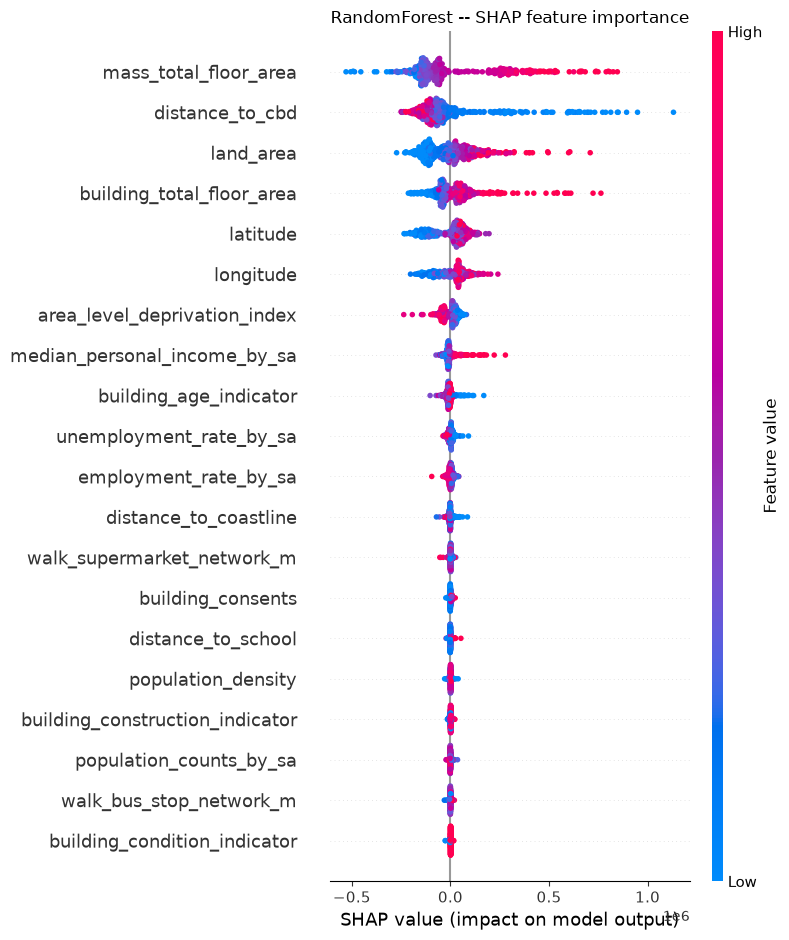

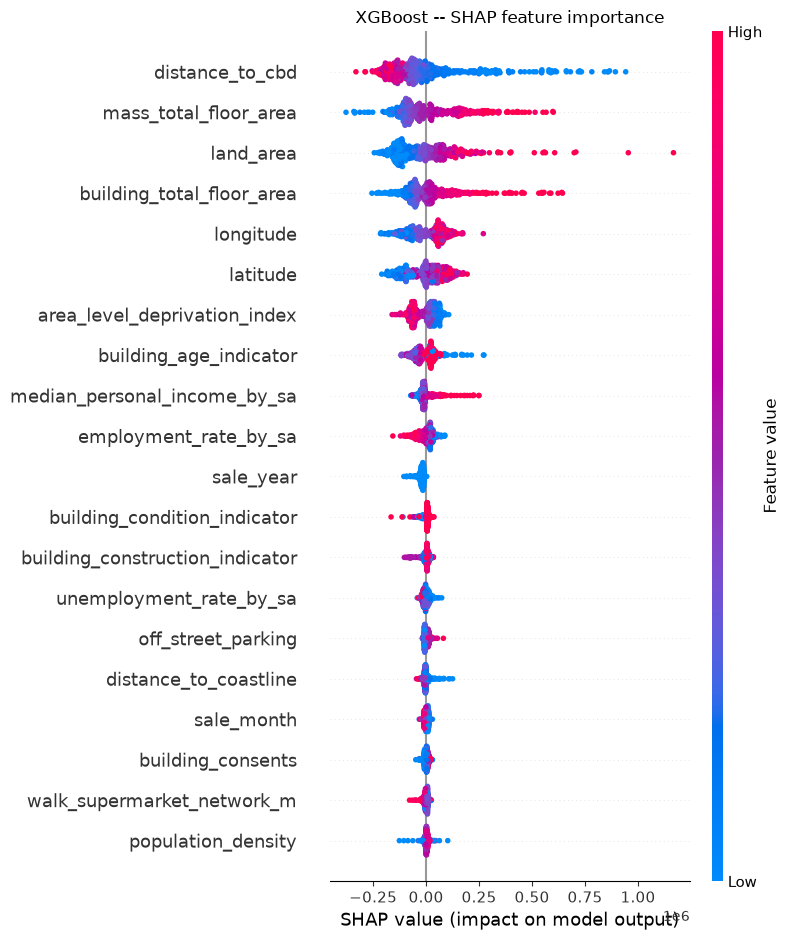

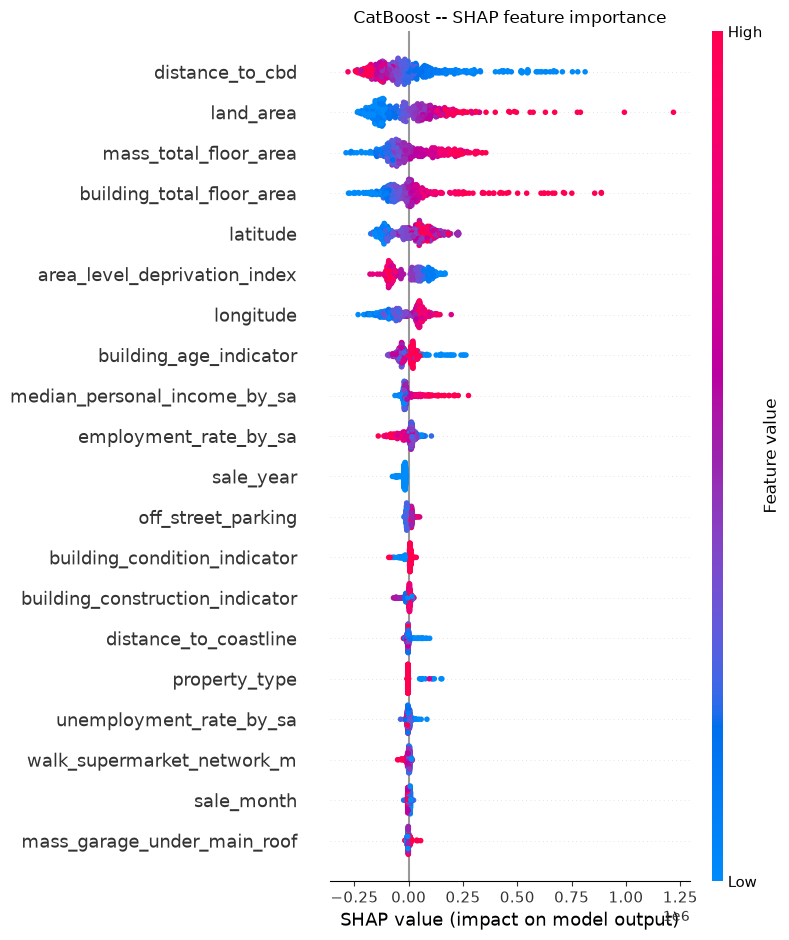

In [12]:
for name, sv in shap_values.items():
    shap.summary_plot(sv, shap_sample, max_display=20, show=False)
    plt.title(f"{name} -- SHAP feature importance")
    plt.tight_layout()
    plt.show()

### 6.2 Side-by-side ranking

Share of each model's total mean |SHAP|, so the three columns are on the
same scale. Sorted by the XGBoost share.

In [13]:
shap_share = pd.DataFrame({
    name: pd.Series(np.abs(sv).mean(axis=0), index=FEATURE_COLS) for name, sv in shap_values.items()
})
shap_share = shap_share / shap_share.sum() * 100
shap_rank = shap_share.rank(ascending=False).astype(int).add_suffix(" rank")

shap_table = pd.concat([shap_share.round(1).add_suffix(" %"), shap_rank], axis=1)
shap_table.sort_values("XGBoost %", ascending=False)

,RandomForest %,XGBoost %,CatBoost %,RandomForest rank,XGBoost rank,CatBoost rank
distance_to_cbd,18.1,16.5,15.1,2,1,1
mass_total_floor_area,24.9,13.4,10.9,1,2,3
land_area,12.9,12.6,14.3,3,3,2
building_total_floor_area,10.3,10.2,10.8,4,4,4
longitude,8.3,8.3,7.7,6,5,7
latitude,9.6,8.0,9.4,5,6,5
area_level_deprivation_index,4.1,5.2,8.4,7,7,6
building_age_indicator,1.8,4.6,4.3,9,8,8
median_personal_income_by_sa,2.9,3.0,3.3,8,9,9
employment_rate_by_sa,1.0,3.0,3.3,11,10,10


## 7. Explaining individual predictions

Pick 10 random houses, predict each one's price, and explain **why** the
model gave that price.

- **Model:** XGBoost (most accurate above), trained on fold 5's training
  period (sales up to January 2026).
- **Honest test:** the 10 houses are drawn at random from fold 5's **test**
  period (January -- August 2026), so the model has never seen them, and
  each prediction can be checked against the real sale price.
- **Explanation:** SHAP splits each prediction into
  `average price + one contribution per feature`, shown as a plain-English
  summary grouped into themes and a waterfall chart in real units.

Needs sections 1--4 only (it trains its own model), not sections 5--6.

In [14]:
import shap
import matplotlib.pyplot as plt
from xgboost import XGBRegressor

house_fold = folds[-1]
house_model = XGBRegressor(
    n_estimators=500, max_depth=6, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1,
)
house_model.fit(house_fold["X_train"], house_fold["y_train"])

houses = house_fold["X_test"].sample(n=10, random_state=7)
house_actual = pd.Series(house_fold["y_test"], index=house_fold["X_test"].index).loc[houses.index]
house_pred = pd.Series(house_model.predict(houses), index=houses.index)

house_shap = shap.TreeExplainer(house_model)(houses)
base_value = float(house_shap.base_values[0])

# SHAP is additive: average + contributions must equal the prediction.
assert np.allclose(house_shap.values.sum(axis=1) + base_value, house_pred.values, rtol=1e-4)
print(f"Model trained on {len(house_fold['y_train']):,} sales up to "
      f"{df.loc[house_fold['X_train'].index, 'sale_date_parsed'].max().date()}")
print(f"Average predicted price (SHAP starting point): ${base_value:,.0f}")

Model trained on 48,774 sales up to 2026-01-24
Average predicted price (SHAP starting point): $1,150,951


### 7.1 Readable values and addresses

The model's inputs include log-transformed sizes and integer category codes.
For the explanations they are converted back to real units (land and floor
area in sqm, distances in km or m, building age as a decade). Addresses come
from the original sales file.

In [15]:
raw = pd.read_parquet(
    "./cache/dvrs_with_team_external.parquet",
    columns=["valuation_id_concat", "sale_date", "sale_price_gross",
             "situation_number", "additional_situation_number", "situation_name"],
)
raw["sale_price_gross"] = pd.to_numeric(raw["sale_price_gross"], errors="coerce")
raw["sale_date_parsed"] = pd.to_datetime(raw["sale_date"].astype(str).str.zfill(8), format="%d%m%Y")
raw["address"] = (
    raw["situation_number"].astype(str)
    + raw["additional_situation_number"].fillna("").astype(str)
    + " " + raw["situation_name"].fillna("").astype(str).str.title()
)
addresses = (
    raw.drop_duplicates(["valuation_id_concat", "sale_date_parsed", "sale_price_gross"])
    .set_index(["valuation_id_concat", "sale_date_parsed", "sale_price_gross"])["address"]
)
key = pd.MultiIndex.from_frame(df.loc[houses.index, ["valuation_id_concat", "sale_date_parsed", "sale_price_gross"]])
house_address = pd.Series(addresses.reindex(key).values, index=houses.index).fillna("(address not found)")


def readable_row(i):
    """Feature values for one house in human units (from the unprocessed data)."""
    r = df.loc[i]
    age = str(r["building_age_indicator"])
    return {
        "property_type": r["property_type"],
        "building_age_indicator": f"{age}0s" if age.isdigit() else age,
        "building_condition_indicator": r["building_condition_indicator"],
        "building_construction_indicator": r["building_construction_indicator"],
        "noise_category_combination": r["noise_category_combination"].replace("_", " "),
        "in_flood_plain": "yes" if r["in_flood_plain"] else "no",
        "land_area": f"{np.expm1(r['land_area']) * 10_000:,.0f} sqm",  # stored in hectares
        "building_total_floor_area": f"{np.expm1(r['building_total_floor_area']):,.0f} sqm",
        "mass_total_floor_area": f"{np.expm1(r['mass_total_floor_area']):,.0f} sqm",
        "off_street_parking": f"{r['off_street_parking']:.0f}",
        "mass_garage_under_main_roof": f"{r['mass_garage_under_main_roof']:.0f}",
        "mass_garage_freestanding": f"{r['mass_garage_freestanding']:.0f}",
        "latitude": f"{r['latitude']:.4f}",
        "longitude": f"{r['longitude']:.4f}",
        "distance_to_cbd": f"{r['distance_to_cbd'] / 1000:.1f} km",
        "walk_supermarket_network_m": "n/a" if pd.isna(r["walk_supermarket_network_m"]) else f"{np.expm1(r['walk_supermarket_network_m']):,.0f} m",
        "walk_bus_stop_network_m": "n/a" if pd.isna(r["walk_bus_stop_network_m"]) else f"{np.expm1(r['walk_bus_stop_network_m']):,.0f} m",
        "distance_to_school": f"{r['distance_to_school']:,.0f} m",
        "area_level_deprivation_index": f"{r['area_level_deprivation_index']:.0f} of 10",
        "median_personal_income_by_sa": f"${r['median_personal_income_by_sa']:,.0f}",
        "employment_rate_by_sa": f"{r['employment_rate_by_sa']:.0f}%",
        "unemployment_rate_by_sa": f"{r['unemployment_rate_by_sa']:.1f}%",
        "population_counts_by_sa": f"{r['population_counts_by_sa']:,.0f}",
        "population_density": f"{r['population_density']:,.0f} per sq km",
        "distance_to_coastline": f"{r['distance_to_coastline']:,.0f} m",
        "building_consents": f"{r['building_consents']:.0f}",
        "sale_year": f"{r['sale_year']:.0f}",
        "sale_month": f"{r['sale_month']:.0f}",
        "sale_quarter": f"Q{r['sale_quarter']:.0f}",
    }


readable = pd.DataFrame([readable_row(i) for i in houses.index], index=houses.index)[FEATURE_COLS]

### 7.2 The 10 houses at a glance

In [16]:
house_summary = pd.DataFrame({
    "address": house_address,
    "sale_date": df.loc[houses.index, "sale_date_parsed"].dt.date,
    "actual_price": house_actual.map("${:,.0f}".format),
    "predicted_price": house_pred.map("${:,.0f}".format),
    "error": ((house_pred - house_actual) / house_actual * 100).map("{:+.1f}%".format),
})
house_summary.index = range(1, len(house_summary) + 1)
house_summary.index.name = "house"
house_summary

,address,sale_date,actual_price,predicted_price,error
house,,,,,
1,119 Waimumu Rd,2026-05-15,"$1,085,000","$959,834",-11.5%
2,8/3 Park Rise,2026-05-20,"$1,495,000","$1,530,707",+2.4%
3,40E Estuary Rd,2026-02-02,"$690,000","$687,840",-0.3%
4,15A Clifton Rd,2026-05-06,"$2,755,000","$3,184,152",+15.6%
5,182 Glamorgan Dr,2026-04-24,"$835,000","$1,108,409",+32.7%
6,3 Uma Gr,2026-04-15,"$765,000","$806,377",+5.4%
7,12B Rewi St,2026-06-01,"$1,285,000","$1,261,136",-1.9%
8,10 Pecan Pl,2026-02-19,"$835,000","$939,700",+12.5%
9,10 Wairua Pl,2026-06-21,"$680,000","$683,442",+0.5%


### 7.3 Why the model gave this price

Explains **one** house -- set `HOUSE` to any number from the 7.2 table
(1--10) to see a different one.

Contributions are grouped into five themes for the summary. Because SHAP
values add up, a theme's contribution is simply the sum of its features'
contributions. The waterfall chart shows the 10 largest individual features
(the rest combined into one bar); red raises the price, blue lowers it, and
the dotted / solid / dashed lines mark the average, predicted and actual
price.

These explain what the **model** learned from past sales -- they are not
proof that a feature causes a price change in the market.

House 7: 12B Rewi St  (sold 2026-06-01)
  Predicted $1,261,136   actual $1,285,000   error -1.9%
  Start from the average predicted price: $1,150,951
        +$57,187  Location         mainly latitude = -36.6966 (+$97,211), distance_to_cbd = 16.9 km (-$74,197)
        +$41,540  House & land     mainly land_area = 186 sqm (-$99,610), mass_total_floor_area = 154 sqm (+$56,455)
        +$28,244  Neighbourhood    mainly area_level_deprivation_index = 2 of 10 (+$45,300), median_personal_income_by_sa = $49,800 (-$9,386)
        -$18,758  Market & timing  mainly sale_year = 2026 (-$11,877), sale_month = 6 (-$7,932)
         +$1,972  Hazards          mainly in_flood_plain = no (+$2,093), noise_category_combination = outside current overlay (-$121)
  = predicted $1,261,136
  In short: the biggest push UP is latitude (-36.6966, +$97,211); the biggest push DOWN is land_area (186 sqm, -$99,610).


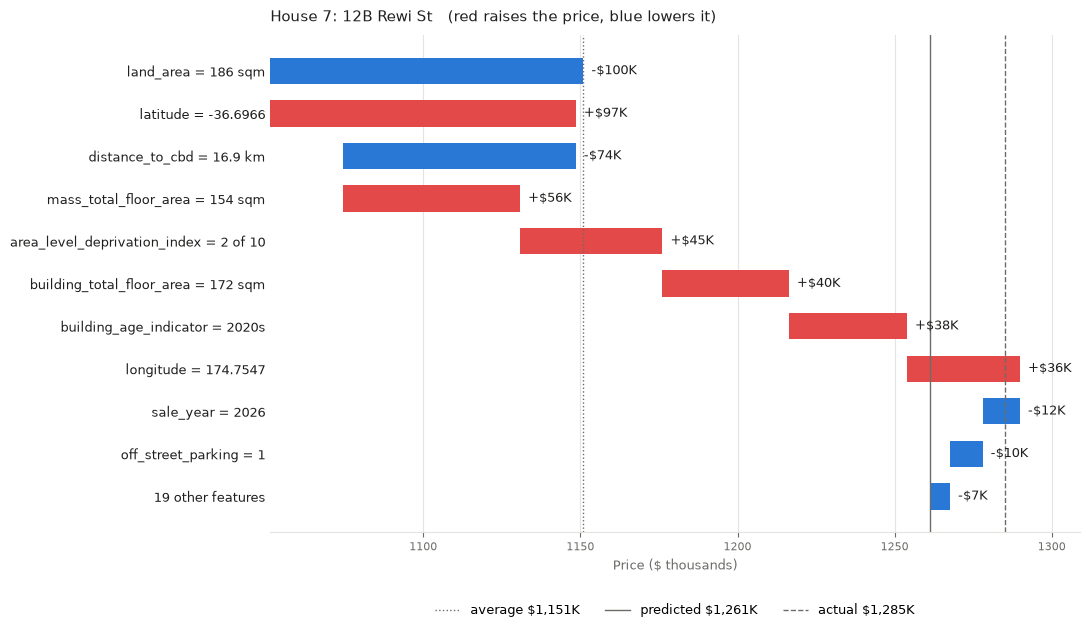

In [17]:
from matplotlib.lines import Line2D

HOUSE = 7  # which house from the 7.2 table to explain (1-10)

THEMES = {
    "Location": ["latitude", "longitude", "distance_to_cbd", "distance_to_coastline",
                 "distance_to_school", "walk_supermarket_network_m", "walk_bus_stop_network_m"],
    "Neighbourhood": ["area_level_deprivation_index", "median_personal_income_by_sa",
                      "employment_rate_by_sa", "unemployment_rate_by_sa",
                      "population_counts_by_sa", "population_density"],
    "House & land": ["land_area", "building_total_floor_area", "mass_total_floor_area",
                     "off_street_parking", "mass_garage_under_main_roof", "mass_garage_freestanding",
                     "building_age_indicator", "building_condition_indicator",
                     "building_construction_indicator", "property_type"],
    "Hazards": ["in_flood_plain", "noise_category_combination"],
    "Market & timing": ["building_consents", "sale_year", "sale_month", "sale_quarter"],
}
assert sorted(sum(THEMES.values(), [])) == sorted(FEATURE_COLS), "every feature must be in exactly one theme"

UP, DOWN = "#e34948", "#2a78d6"          # raises / lowers the price
INK, INK_MUTED, GRID = "#1f1f1e", "#6b6b68", "#e4e3df"


def money(x):
    return f"{'+' if x >= 0 else '-'}${abs(x):,.0f}"


def mpl(s):
    # A bare "$" switches matplotlib into maths formatting, so escape it.
    return s.replace("$", "\\$")


i = houses.index[HOUSE - 1]
contrib = pd.Series(house_shap.values[HOUSE - 1], index=FEATURE_COLS)
themes = pd.Series({t: contrib[cols].sum() for t, cols in THEMES.items()})
err = (house_pred[i] - house_actual[i]) / house_actual[i] * 100

# Plain-English summary
print(f"House {HOUSE}: {house_address[i]}  (sold {df.loc[i, 'sale_date_parsed'].date()})")
print(f"  Predicted ${house_pred[i]:,.0f}   actual ${house_actual[i]:,.0f}   error {err:+.1f}%")
print(f"  Start from the average predicted price: ${base_value:,.0f}")
for theme, value in themes.sort_values(key=abs, ascending=False).items():
    top = contrib[THEMES[theme]].sort_values(key=abs, ascending=False).head(2)
    detail = ", ".join(f"{f} = {readable.loc[i, f]} ({money(v)})" for f, v in top.items())
    print(f"    {money(value):>12}  {theme:<16} mainly {detail}")
print(f"  = predicted ${house_pred[i]:,.0f}")
up, down = contrib.idxmax(), contrib.idxmin()
print(f"  In short: the biggest push UP is {up} ({readable.loc[i, up]}, {money(contrib[up])}); "
      f"the biggest push DOWN is {down} ({readable.loc[i, down]}, {money(contrib[down])}).")

# Waterfall: bars run from the average price to the prediction, one step per feature.
order = contrib.abs().sort_values(ascending=False).index
steps = list(contrib[order[:10]].items()) + [(f"{len(order) - 10} other features", contrib[order[10:]].sum())]
labels = [f"{f} = {readable.loc[i, f]}" if f in readable.columns else f for f, _ in steps]

fig, ax = plt.subplots(figsize=(11, 0.42 * len(steps) + 1.8))
level = base_value
for row, (_, v) in enumerate(steps):
    ax.barh(row, v / 1000, left=level / 1000, height=0.62, color=UP if v >= 0 else DOWN)
    ax.text(max(level, level + v) / 1000, row, mpl(f"  {'+' if v >= 0 else '-'}${abs(v) / 1000:,.0f}K"),
            va="center", ha="left", fontsize=9, color=INK)
    level += v

reference = [
    (base_value, f"average ${base_value / 1000:,.0f}K", ":"),
    (house_pred[i], f"predicted ${house_pred[i] / 1000:,.0f}K", "-"),
    (house_actual[i], f"actual ${house_actual[i] / 1000:,.0f}K", "--"),
]
for value, _, style in reference:
    ax.axvline(value / 1000, color=INK_MUTED, linestyle=style, linewidth=1)
ax.legend(
    handles=[Line2D([], [], color=INK_MUTED, linestyle=s, linewidth=1, label=mpl(t)) for _, t, s in reference],
    loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False, fontsize=9,
)

ax.set_yticks(range(len(steps)))
ax.set_yticklabels([mpl(l) for l in labels], fontsize=9, color=INK)
ax.invert_yaxis()
ax.set_xlabel(mpl("Price ($ thousands)"), fontsize=9, color=INK_MUTED)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(axis="x", colors=INK_MUTED, labelsize=8)
ax.tick_params(axis="y", length=0)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
left, right = ax.get_xlim()
ax.set_xlim(left, right + (right - left) * 0.08)  # room for the last label
ax.set_title(f"House {HOUSE}: {house_address[i]}   (red raises the price, blue lowers it)",
             loc="left", fontsize=11, color=INK, pad=10)
plt.tight_layout()
plt.show()